# Brazilian E-Commerce Sales and Customer Analysis

### Exploring Sales, Customers, Products, Sellers, Payments, Delivery and Reviews
*Tools Used:* Python, Pandas, NumPy, Matplotlib and Seaborn

*Dataset Source:* Olist Brazilian E-Commerce Public Dataset


## 1. Project Overview

This project analyses the Brazilian E-Commerce Public Dataset provided by Olist.

The dataset contains information related to orders, customers, products, sellers, payments, reviews and delivery. The data is distributed across multiple related CSV files.

The objective of this project is to clean, transform and integrate these datasets and perform Exploratory Data Analysis (EDA) to identify meaningful patterns in e-commerce sales and customer behaviour.

The analysis focuses on sales performance, product categories, customer locations, payment methods, seller activity, delivery performance and customer satisfaction.

## 2. Problem Statement

The Olist e-commerce dataset contains information spread across multiple tables, making it difficult to directly analyse the overall business performance.

The purpose of this project is to integrate the related datasets, perform data cleaning and preprocessing, and analyse the resulting data to answer important business questions.

### Key Questions

1. How did sales change over time?
2. Which product categories generated the highest sales?
3. Which Brazilian states contributed the most orders?
4. What payment methods were most commonly used?
5. How were customer review scores distributed?
6. How long did customers wait for their orders?
7. Is delivery performance related to customer satisfaction?
8. Which sellers and product categories contributed significantly to sales?

## 3. Dataset Description

The Olist dataset contains 9 CSV files:

| Dataset | Description |
|---|---|
| olist_orders_dataset | Order status and order timestamps |
| olist_order_items_dataset | Products, sellers, prices and freight |
| olist_customers_dataset | Customer information and location |
| olist_products_dataset | Product attributes |
| olist_sellers_dataset | Seller information and location |
| olist_order_payments_dataset | Payment information |
| olist_order_reviews_dataset | Customer review information |
| product_category_name_translation | Portuguese to English product category translation |
| olist_geolocation_dataset | Brazilian ZIP-code geographic information |

The tables are related through identifiers such as order_id, customer_id, product_id and seller_id.

## 4. Import Required Libraries

The following Python libraries are used for data manipulation, numerical operations, data visualization and statistical exploration

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

## 5. Loading the Datasets

The original Olist dataset contains multiple CSV files. Each file represents a different business entity or transaction-related information.

The datasets are loaded separately first. This allows us to inspect the structure and quality of each table before merging them

In [2]:
orders = pd.read_csv("olist_orders_dataset.csv")

customers = pd.read_csv("olist_customers_dataset.csv")

order_items = pd.read_csv("olist_order_items_dataset.csv")

products = pd.read_csv("olist_products_dataset.csv")

sellers = pd.read_csv("olist_sellers_dataset.csv")

payments = pd.read_csv("olist_order_payments_dataset.csv")

reviews = pd.read_csv("olist_order_reviews_dataset.csv")

translation = pd.read_csv("product_category_name_translation.csv")

geolocation = pd.read_csv("olist_geolocation_dataset.csv")
print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Order Items": order_items,
    "Products": products,
    "Sellers": sellers,
    "Payments": payments,
    "Reviews": reviews,
    "Translation": translation,
    "Geolocation": geolocation
}

print("Dataset dictionary created successfully!")

Dataset dictionary created successfully!


# INITIAL DATA EXPLORATION

## 6. Checking Dataset Dimensions

The shape of each dataset is checked to determine the number of rows and columns present in the individual tables.

This is useful for understanding the size of the data before performing cleaning and merging operations

In [4]:
print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Payments:", payments.shape)
print("Reviews:", reviews.shape)
print("Translation:", translation.shape)
print("Geolocation:", geolocation.shape)

Orders: (99441, 8)
Customers: (99441, 5)
Order Items: (112650, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Payments: (103886, 5)
Reviews: (99224, 7)
Translation: (71, 2)
Geolocation: (1000163, 5)


### Observation

The datasets contain different numbers of rows and columns because each table represents a different entity or transaction level.

For example, one order can contain multiple order items, and an order can also have multiple payment records. Therefore, the number of records differs between tables.

## View First Five Records

## 7. Previewing the Datasets

The first five records of the main datasets are displayed to understand their columns and the type of information stored in each table.

In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


## 8. Checking Dataset Information

The `info()` function is used to examine column names, data types and the number of non-null values.

This helps identify columns that require data type conversion, especially date and timestamp columns.

In [10]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [11]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [12]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [13]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


## 9. Checking Missing Values

Missing values can affect calculations and visualizations. Therefore, missing values are identified before performing data transformation and analysis.

In [14]:
datasets = {
    "Orders": orders,
    "Customers": customers,
    "Order Items": order_items,
    "Products": products,
    "Sellers": sellers,
    "Payments": payments,
    "Reviews": reviews,
    "Translation": translation,
    "Geolocation": geolocation
}

for name, df in datasets.items():
    print("\n", name)
    print(df.isnull().sum())


 Orders
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

 Customers
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

 Order Items
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

 Products
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_

### Observation

The missing-value results will be examined column by column. Missing values are not automatically replaced with zero because the appropriate treatment depends on the meaning and data type of each column.

## 10. Checking Duplicate Records

Duplicate records are checked because duplicated observations can affect statistical calculations and sales analysis.

In [15]:
for name, df in datasets.items():
    print(name, ":", df.duplicated().sum(), "duplicate rows")

Orders : 0 duplicate rows
Customers : 0 duplicate rows
Order Items : 0 duplicate rows
Products : 0 duplicate rows
Sellers : 0 duplicate rows
Payments : 0 duplicate rows
Reviews : 0 duplicate rows
Translation : 0 duplicate rows
Geolocation : 261831 duplicate rows


### Observation

The duplicate counts are reviewed for each dataset. Duplicate handling will be performed only where appropriate, because repeated records can sometimes represent legitimate transactions rather than accidental duplicates.

# DATA CLEANING

## 11. Converting Date and Time Columns

Several columns in the orders dataset contain dates and timestamps stored as text.

These columns are converted into datetime format so that delivery duration, monthly trends and yearly trends can be calculated accurately.

In [16]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

In [17]:
orders[date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

### Check missing values in important order dates

In [18]:
orders[date_columns].isnull().sum()

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

### Observation

Some order timestamps may contain missing values because not every order reached every stage of the delivery process. For example, cancelled or unavailable orders may not have a customer delivery date.

These missing dates will not be replaced with artificial dates because doing so could create incorrect delivery-duration calculations.

# MERGING THE TABLES

# 12. Data Integration and Table Merging

The Olist dataset is divided into multiple related tables.

To perform combined analysis, the relevant tables need to be integrated using common key columns.

The main relationships are:

- `orders` → `customers` using `customer_id`
- `orders` → `order_items` using `order_id`
- `order_items` → `products` using `product_id`
- `order_items` → `sellers` using `seller_id`
- `orders` → `payments` using `order_id`
- `orders` → `reviews` using `order_id`
- `products` → `translation` using `product_category_name`

A LEFT JOIN is used so that all records from the main/base dataset are retained while matching information from the related table is added.

## 13. Creating the Base Dataset

The `orders` table is selected as the starting point because `order_id` is the central identifier connecting order information with customers, items, payments and reviews.

A copy is created so that the original dataset remains unchanged.

In [19]:
master_df = orders.copy()

master_df.shape

(99441, 8)

## 14. Merging Orders with Customer Information

The orders and customers tables are connected through `customer_id`.

A LEFT JOIN is performed using `customer_id`.

The orders table is kept as the left table so that all orders are retained while customer information is added where a matching customer record exists.

In [20]:
master_df = master_df.merge(
    customers,
    on="customer_id",
    how="left"
)

In [21]:
master_df.shape

(99441, 12)

In [22]:
master_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


### Observation

Customer location and customer identification information has now been added to the order-level dataset.

The LEFT JOIN preserves the records from the orders table.

## 15. Merging Order Items

The order items table contains information about individual products purchased within an order.

The common key between the two datasets is `order_id`.

A LEFT JOIN is used to add order-item information to the master dataset.

An important point is that one order can contain multiple items. Therefore, the number of rows can increase after this merge. This is expected because the resulting dataset is now at the order-item level.

In [23]:
master_df = master_df.merge(
    order_items,
    on="order_id",
    how="left"
)

In [24]:
master_df.shape

(113425, 18)

In [25]:
master_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


### Observation

The number of rows increased after merging because an individual order may contain multiple products.

The resulting master dataset represents individual order items while retaining the order and customer information.

## 16. Merging Product Information

The order items table contains `product_id`, which can be used to connect each order item with the corresponding product information.

A LEFT JOIN is performed using `product_id`.

In [26]:
master_df = master_df.merge(
    products,
    on="product_id",
    how="left"
)

In [27]:
master_df.shape

(113425, 26)

## 17. Merging Seller Information

Each order item is associated with a seller through `seller_id`.

Seller information such as seller city, state and ZIP code is added using a LEFT JOIN.

In [28]:
master_df = master_df.merge(
    sellers,
    on="seller_id",
    how="left"
)

In [29]:
master_df.shape

(113425, 29)

## 18. Merging Product Category Translation

The original product category names are provided in Portuguese.

The translation table contains the English equivalent of the category names.

The two tables are connected through `product_category_name`.

In [30]:
master_df = master_df.merge(
    translation,
    on="product_category_name",
    how="left"
)

In [31]:
master_df = master_df.merge(
    translation,
    on="product_category_name",
    how="left"
)

## 19. Preparing Payment Data Before Merging

The payment table can contain multiple records for the same order.

Directly merging the raw payment table with the order-item-level master dataset could create unnecessary row multiplication.

Therefore, the payment data is aggregated at the order level before performing the LEFT JOIN.

The total payment value is calculated by summing payment values for each order.

In [32]:
payment_summary = (
    payments
    .groupby("order_id")
    .agg(
        total_payment_value=("payment_value", "sum"),
        payment_count=("payment_type", "count"),
        max_installments=("payment_installments", "max")
    )
    .reset_index()
)

In [33]:
payment_summary.head()

,order_id,total_payment_value,payment_count,max_installments
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1,2
1,00018f77f2f0320c557190d7a144bdd3,259.83,1,3
2,000229ec398224ef6ca0657da4fc703e,216.87,1,5
3,00024acbcdf0a6daa1e931b038114c75,25.78,1,2
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1,3


### merge

In [34]:
master_df = master_df.merge(
    payment_summary,
    on="order_id",
    how="left"
)

## 20. Preparing Review Data Before Merging

The review table can contain more than one record associated with an order.

To avoid unnecessary row multiplication, the review information is summarized at the order level before merging.

The average review score is calculated for each order.

In [35]:
review_summary = (
    reviews
    .groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

In [36]:
review_summary.head()

,order_id,average_review_score,review_count
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1
1,00018f77f2f0320c557190d7a144bdd3,4.0,1
2,000229ec398224ef6ca0657da4fc703e,5.0,1
3,00024acbcdf0a6daa1e931b038114c75,4.0,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1


### merge

In [37]:
master_df = master_df.merge(
    review_summary,
    on="order_id",
    how="left"
)

## 21. Preparing Geolocation Data

The geolocation dataset may contain multiple latitude and longitude records for the same ZIP-code prefix.

Therefore, the data is aggregated by ZIP-code prefix before merging.

The mean latitude and longitude are used as representative coordinates for each ZIP-code prefix.

In [38]:
geo_summary = (
    geolocation
    .groupby("geolocation_zip_code_prefix")
    .agg(
        latitude=("geolocation_lat", "mean"),
        longitude=("geolocation_lng", "mean")
    )
    .reset_index()
)

In [39]:
# Now customer location:
customer_geo = geo_summary.rename(
    columns={
        "geolocation_zip_code_prefix": "customer_zip_code_prefix",
        "latitude": "customer_latitude",
        "longitude": "customer_longitude"
    }
)

In [40]:
# merge
master_df = master_df.merge(
    customer_geo,
    on="customer_zip_code_prefix",
    how="left"
)

In [41]:
seller_geo = geo_summary.rename(
    columns={
        "geolocation_zip_code_prefix": "seller_zip_code_prefix",
        "latitude": "seller_latitude",
        "longitude": "seller_longitude"
    }
)

In [42]:
master_df = master_df.merge(
    seller_geo,
    on="seller_zip_code_prefix",
    how="left"
)

### Observation

The geolocation information has been aggregated before merging to avoid unnecessary duplication of order-item records.

The resulting master dataset now contains customer and seller geographic information where matching ZIP-code information is available.

## 22. Final Master Dataset

After completing the required LEFT JOIN operations, the resulting master dataset combines information from the major Olist tables.

The final dataset can now be used for feature engineering and exploratory data analysis.

In [43]:
master_df.shape

(113425, 40)

In [44]:
master_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,product_category_name_english_y,total_payment_value,payment_count,max_installments,average_review_score,review_count,customer_latitude,customer_longitude,seller_latitude,seller_longitude
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,housewares,38.71,3.0,1.0,4.0,1.0,-23.576983,-46.587161,-23.680729,-46.444238
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,perfumery,141.46,1.0,1.0,4.0,1.0,-12.177924,-44.660711,-19.807681,-43.980427
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,auto,179.12,1.0,3.0,5.0,1.0,-16.745150,-48.514783,-21.363502,-48.229601
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,59296,...,pet_shop,72.20,1.0,1.0,5.0,1.0,-5.774190,-35.271143,-19.837682,-43.924053
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,stationery,28.62,1.0,1.0,5.0,1.0,-23.676370,-46.514627,-23.543395,-46.262086


In [45]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113425 entries, 0 to 113424
Data columns (total 40 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   order_id                         113425 non-null  object        
 1   customer_id                      113425 non-null  object        
 2   order_status                     113425 non-null  object        
 3   order_purchase_timestamp         113425 non-null  datetime64[ns]
 4   order_approved_at                113264 non-null  datetime64[ns]
 5   order_delivered_carrier_date     111457 non-null  datetime64[ns]
 6   order_delivered_customer_date    110196 non-null  datetime64[ns]
 7   order_estimated_delivery_date    113425 non-null  datetime64[ns]
 8   customer_unique_id               113425 non-null  object        
 9   customer_zip_code_prefix         113425 non-null  int64         
 10  customer_city                    113425 non-

## 23. Creating Derived Features

Derived features are created from existing columns to support deeper analysis.

For the order-item-level dataset, item revenue is calculated as product price plus freight value.

In [46]:
master_df["item_revenue"] = (
    master_df["price"] + master_df["freight_value"]
)

## 25. Extract Year, Month and Day

In [47]:

master_df["purchase_year"] = (
    master_df["order_purchase_timestamp"].dt.year
)

master_df["purchase_month"] = (
    master_df["order_purchase_timestamp"].dt.month
)

master_df["purchase_month_name"] = (
    master_df["order_purchase_timestamp"].dt.strftime("%B")
)

master_df["purchase_day"] = (
    master_df["order_purchase_timestamp"].dt.day
)

## 24. Calculating Delivery Duration

Delivery duration is calculated as the number of days between the purchase timestamp and the date on which the customer received the order.

Orders without a customer delivery date will result in missing delivery duration values because the order did not have a completed delivery record.

In [48]:
master_df["delivery_days"] = (
    master_df["order_delivered_customer_date"]
    - master_df["order_purchase_timestamp"]
).dt.days

## 25. Calculating Delivery Delay

Delivery delay is calculated by comparing the actual customer delivery date with the estimated delivery date.

A positive value indicates delivery after the estimated date, while a negative value indicates delivery before the estimated date.

In [49]:
master_df["delivery_delay_days"] = (
    master_df["order_delivered_customer_date"]
    - master_df["order_estimated_delivery_date"]
).dt.days

## 28. Create Purchase Month-Year

In [50]:

master_df["purchase_month_year"] = (
    master_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

## 29. Removing Unnecessary and Duplicate Columns

After merging the required datasets, the master dataset contains some unnecessary columns and duplicate fields.

The duplicate product category columns created during the merging process are combined into a single English product category column.

Columns that are not required for the planned analysis are then removed to reduce the size and complexity of the dataset.

In [51]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_zip_code_prefix',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'product_category_name',
 'product_name_lenght',
 'product_description_lenght',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm',
 'seller_zip_code_prefix',
 'seller_city',
 'seller_state',
 'product_category_name_english_x',
 'product_category_name_english_y',
 'total_payment_value',
 'payment_count',
 'max_installments',
 'average_review_score',
 'review_count',
 'customer_latitude',
 'customer_longitude',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'deli

In [52]:
# # Create a backup before final cleaning
master_df_before_final_cleaning = master_df.copy()

print("Original merged dataset shape:", master_df.shape)

Original merged dataset shape: (113425, 48)


In [53]:
# Combine the two duplicate English category columns
master_df["product_category_name_english"] = (
    master_df["product_category_name_english_x"]
    .combine_first(master_df["product_category_name_english_y"])
)

## Remove unnecessary columns

In [54]:
unnecessary_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "customer_zip_code_prefix",
    "shipping_limit_date",
    "product_category_name",
    "product_name_length",
    "product_description_length",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "seller_zip_code_prefix",
    "payment_count",
    "max_installments",
    "review_count",
    "customer_latitude",
    "customer_longitude",
    "product_category_name_english_x",
    "product_category_name_english_y"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

### why these are removed
I don’t need all product dimensions, ZIP codes, latitude/longitude, duplicate category columns, etc. for the analysis  planned.

Not deleting the original orders, products, payments, etc. tables. Here only reducing the columns in the final master_df.

In [55]:
print("Shape after removing unnecessary columns:", master_df.shape)

Shape after removing unnecessary columns: (113425, 31)


In [56]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

In [57]:
master_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,order_item_id,...,seller_longitude,item_revenue,purchase_year,purchase_month,purchase_month_name,purchase_day,delivery_days,delivery_delay_days,purchase_month_year,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,...,-46.444238,38.71,2017,10,October,2,8.0,-8.0,2017-10,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,1.0,...,-43.980427,141.46,2018,7,July,24,13.0,-6.0,2018-07,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,1.0,...,-48.229601,179.12,2018,8,August,8,9.0,-18.0,2018-08,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,1.0,...,-43.924053,72.20,2017,11,November,18,13.0,-13.0,2017-11,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,1.0,...,-46.262086,28.62,2018,2,February,13,2.0,-10.0,2018-02,stationery


### Observation

Unnecessary and duplicate columns have been removed from the merged dataset. The remaining variables are focused on orders, customers, products, sellers, sales, payments, reviews and delivery performance.

## Remove Null Values

## Handling Missing Values in the Merged Dataset

After removing unnecessary columns, missing values are checked again in the final master dataset.

Missing values may occur after LEFT JOIN operations when corresponding information is not available in a related table.

The remaining null values are removed before performing further analysis.

In [58]:
null_summary = (
    master_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

null_summary[null_summary > 0]

delivery_delay_days              3229
delivery_days                    3229
order_delivered_customer_date    3229
product_category_name_english    2402
product_name_lenght              2378
product_description_lenght       2378
seller_longitude                 1028
seller_latitude                  1028
average_review_score              961
item_revenue                      775
order_item_id                     775
product_id                        775
seller_id                         775
price                             775
freight_value                     775
seller_city                       775
seller_state                      775
total_payment_value                 3
dtype: int64

In [59]:
print("Total null values:", master_df.isnull().sum().sum())

Total null values: 26065


In [60]:
unnecessary_columns = [
    "product_description_length",
    "product_name_length"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print(master_df.shape)

(113425, 31)


In [61]:
unnecessary_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "customer_zip_code_prefix",
    "shipping_limit_date",
    "product_category_name",
    "product_description_length",
    "product_name_length",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "seller_zip_code_prefix",
    "payment_count",
    "max_installments",
    "review_count",
    "customer_latitude",
    "customer_longitude"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

In [62]:
#### check nulls again
null_summary = (
    master_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

null_summary[null_summary > 0]

delivery_delay_days              3229
delivery_days                    3229
order_delivered_customer_date    3229
product_category_name_english    2402
product_name_lenght              2378
product_description_lenght       2378
seller_longitude                 1028
seller_latitude                  1028
average_review_score              961
item_revenue                      775
order_item_id                     775
product_id                        775
seller_id                         775
price                             775
freight_value                     775
seller_city                       775
seller_state                      775
total_payment_value                 3
dtype: int64

In [63]:
print("Total null values:", master_df.isnull().sum().sum())

Total null values: 26065


In [64]:
# Remove unnecessary columns from the merged dataset

unnecessary_columns = [
    "product_name_length",
    "product_description_length",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "customer_zip_code_prefix",
    "seller_zip_code_prefix",
    "customer_latitude",
    "customer_longitude",
    "order_approved_at",
    "order_delivered_carrier_date",
    "shipping_limit_date",
    "payment_count",
    "max_installments",
    "review_count",
    "product_category_name"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print("Current dataset shape:", master_df.shape)

Current dataset shape: (113425, 31)


In [65]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

In [66]:
# Remove unnecessary product columns

master_df = master_df.drop(
    columns=[
        "product_name_length",
        "product_description_length"
    ],
    errors="ignore"
)

print("Current dataset shape:", master_df.shape)

Current dataset shape: (113425, 31)


In [67]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

In [68]:
# Remove unnecessary product columns

master_df = master_df.drop(
    columns=[
        "product_name_length",
        "product_description_length"
    ],
    errors="ignore"
)

print("Columns removed successfully.")
print("Current dataset shape:", master_df.shape)

Columns removed successfully.
Current dataset shape: (113425, 31)


In [69]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

In [70]:
"product_name_length" in master_df.columns

False

In [71]:
"product_description_length" in master_df.columns

False

In [72]:
# Remove other unnecessary columns

unnecessary_columns = [
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "customer_zip_code_prefix",
    "seller_zip_code_prefix",
    "customer_latitude",
    "customer_longitude",
    "order_approved_at",
    "order_delivered_carrier_date",
    "shipping_limit_date",
    "payment_count",
    "max_installments",
    "review_count",
    "product_category_name"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print("Other unnecessary columns removed.")
print("Current dataset shape:", master_df.shape)

Other unnecessary columns removed.
Current dataset shape: (113425, 31)


In [73]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

In [74]:
print("product_name_length" in master_df.columns)
print("product_description_length" in master_df.columns)

False
False


In [75]:
# Remove other unnecessary columns

unnecessary_columns = [
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "customer_zip_code_prefix",
    "seller_zip_code_prefix",
    "customer_latitude",
    "customer_longitude",
    "order_approved_at",
    "order_delivered_carrier_date",
    "shipping_limit_date",
    "payment_count",
    "max_installments",
    "review_count",
    "product_category_name"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print("Current dataset shape:", master_df.shape)

Current dataset shape: (113425, 31)


In [76]:
master_df.columns.tolist()

['order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_delivered_customer_date',
 'order_estimated_delivery_date',
 'customer_unique_id',
 'customer_city',
 'customer_state',
 'order_item_id',
 'product_id',
 'seller_id',
 'price',
 'freight_value',
 'product_name_lenght',
 'product_description_lenght',
 'seller_city',
 'seller_state',
 'total_payment_value',
 'average_review_score',
 'seller_latitude',
 'seller_longitude',
 'item_revenue',
 'purchase_year',
 'purchase_month',
 'purchase_month_name',
 'purchase_day',
 'delivery_days',
 'delivery_delay_days',
 'purchase_month_year',
 'product_category_name_english']

## Handling Missing Values

After removing unnecessary columns, the remaining missing values in the merged dataset are checked.

Missing values can occur because some related records are not available after the LEFT JOIN operations. The remaining records with missing values are removed to prepare the dataset for further analysis.

### check remaining nulls

In [77]:
null_summary = (
    master_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

null_summary[null_summary > 0]

delivery_delay_days              3229
delivery_days                    3229
order_delivered_customer_date    3229
product_category_name_english    2402
product_name_lenght              2378
product_description_lenght       2378
seller_longitude                 1028
seller_latitude                  1028
average_review_score              961
item_revenue                      775
order_item_id                     775
product_id                        775
seller_id                         775
price                             775
freight_value                     775
seller_city                       775
seller_state                      775
total_payment_value                 3
dtype: int64

In [78]:
print("Total null values:", master_df.isnull().sum().sum())

Total null values: 26065


In [79]:
# Check the current dataset after removing unnecessary columns

print("Current dataset shape:", master_df.shape)

print("\nCurrent columns:")
print(master_df.columns.tolist())

print("\nCurrent total null values:")
print(master_df.isnull().sum().sum())

Current dataset shape: (113425, 31)

Current columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']

Current total null values:
26065


In [80]:
# Remove unnecessary columns from the final master dataset

unnecessary_columns = [
    "product_name_length",
    "product_description_length",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "customer_zip_code_prefix",
    "seller_zip_code_prefix",
    "customer_latitude",
    "customer_longitude",
    "order_approved_at",
    "order_delivered_carrier_date",
    "shipping_limit_date",
    "payment_count",
    "max_installments",
    "review_count",
    "product_category_name"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print("Unnecessary columns removed.")
print("Current dataset shape:", master_df.shape)

Unnecessary columns removed.
Current dataset shape: (113425, 31)


In [81]:
print(master_df.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


In [82]:
null_summary = (
    master_df.isnull()
    .sum()
    .sort_values(ascending=False)
)

null_summary[null_summary > 0]

delivery_delay_days              3229
delivery_days                    3229
order_delivered_customer_date    3229
product_category_name_english    2402
product_name_lenght              2378
product_description_lenght       2378
seller_longitude                 1028
seller_latitude                  1028
average_review_score              961
item_revenue                      775
order_item_id                     775
product_id                        775
seller_id                         775
price                             775
freight_value                     775
seller_city                       775
seller_state                      775
total_payment_value                 3
dtype: int64

In [83]:
print("Total null values:", master_df.isnull().sum().sum())

Total null values: 26065


In [84]:
# Remove rows containing missing values

rows_before = master_df.shape[0]

master_df = master_df.dropna().reset_index(drop=True)

rows_after = master_df.shape[0]

print("Rows before null removal:", rows_before)
print("Rows after null removal:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before null removal: 113425
Rows after null removal: 107571
Rows removed: 5854


In [85]:
print("Remaining null values:", master_df.isnull().sum().sum())

Remaining null values: 0


In [86]:
print("Final shape:", master_df.shape)
print("Remaining null values:", master_df.isnull().sum().sum())
print("Duplicate rows:", master_df.duplicated().sum())

Final shape: (107571, 31)
Remaining null values: 0
Duplicate rows: 0


In [87]:
# Remove unnecessary columns from the cleaned master dataset

unnecessary_columns = [
    "product_name_length",
    "product_description_length",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "customer_zip_code_prefix",
    "seller_zip_code_prefix",
    "customer_latitude",
    "customer_longitude",
    "order_approved_at",
    "order_delivered_carrier_date",
    "shipping_limit_date",
    "payment_count",
    "max_installments",
    "review_count",
    "product_category_name"
]

master_df = master_df.drop(
    columns=unnecessary_columns,
    errors="ignore"
)

print("Unnecessary columns removed.")
print("New dataset shape:", master_df.shape)

Unnecessary columns removed.
New dataset shape: (107571, 31)


In [88]:
print(master_df.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


In [89]:
print("product_name_length" in master_df.columns)
print("product_description_length" in master_df.columns)

False
False


In [90]:
print("CURRENT DATASET SHAPE:", master_df.shape)

print("\nCURRENT COLUMNS:")
for col in master_df.columns:
    print(col)

CURRENT DATASET SHAPE: (107571, 31)

CURRENT COLUMNS:
order_id
customer_id
order_status
order_purchase_timestamp
order_delivered_customer_date
order_estimated_delivery_date
customer_unique_id
customer_city
customer_state
order_item_id
product_id
seller_id
price
freight_value
product_name_lenght
product_description_lenght
seller_city
seller_state
total_payment_value
average_review_score
seller_latitude
seller_longitude
item_revenue
purchase_year
purchase_month
purchase_month_name
purchase_day
delivery_days
delivery_delay_days
purchase_month_year
product_category_name_english


In [91]:
# FINAL REMOVE: unwanted columns

cols_to_remove = [
    "product_name_length",
    "product_description_length"
]

print("Before:", [c for c in cols_to_remove if c in master_df.columns])

master_df.drop(
    columns=[c for c in cols_to_remove if c in master_df.columns],
    inplace=True
)

print("After:", [c for c in cols_to_remove if c in master_df.columns])
print("New shape:", master_df.shape)

Before: []
After: []
New shape: (107571, 31)


In [92]:
print("Number of columns:", len(master_df.columns))
print("\nCurrent columns:")
for i, col in enumerate(master_df.columns, 1):
    print(i, col)

Number of columns: 31

Current columns:
1 order_id
2 customer_id
3 order_status
4 order_purchase_timestamp
5 order_delivered_customer_date
6 order_estimated_delivery_date
7 customer_unique_id
8 customer_city
9 customer_state
10 order_item_id
11 product_id
12 seller_id
13 price
14 freight_value
15 product_name_lenght
16 product_description_lenght
17 seller_city
18 seller_state
19 total_payment_value
20 average_review_score
21 seller_latitude
22 seller_longitude
23 item_revenue
24 purchase_year
25 purchase_month
26 purchase_month_name
27 purchase_day
28 delivery_days
29 delivery_delay_days
30 purchase_month_year
31 product_category_name_english


In [93]:
# Safely remove unwanted columns if they exist

unwanted_columns = [
    "product_name_length",
    "product_description_length"
]

existing_columns = [
    col for col in unwanted_columns
    if col in master_df.columns
]

master_df = master_df.drop(columns=existing_columns)

print("Removed columns:", existing_columns)
print("Current dataset shape:", master_df.shape)

Removed columns: []
Current dataset shape: (107571, 31)


In [94]:
print("Number of columns:", len(master_df.columns))
print(master_df.columns.tolist())

Number of columns: 31
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'product_name_lenght', 'product_description_lenght', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


In [95]:
# Remove columns 15 and 16: product name length and product description length

master_df = master_df.drop(master_df.columns[[14, 15]], axis=1)

print("Columns removed successfully.")
print("New dataset shape:", master_df.shape)

Columns removed successfully.
New dataset shape: (107571, 29)


In [96]:
print("Number of columns:", len(master_df.columns))
print(master_df.columns.tolist())

Number of columns: 29
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


## Outlier detection & removal

In [97]:
# Check numeric columns
numeric_columns = master_df.select_dtypes(include='number').columns

print("Numeric columns:")
print(numeric_columns.tolist())

Numeric columns:
['order_item_id', 'price', 'freight_value', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_day', 'delivery_days', 'delivery_delay_days']


In [98]:
# Detect outliers using the IQR method

outlier_columns = [
    "price",
    "freight_value",
    "total_payment_value",
    "average_review_score",
    "item_revenue",
    "delivery_days",
    "delivery_delay_days"
]

outlier_summary = {}

for col in outlier_columns:
    Q1 = master_df[col].quantile(0.25)
    Q3 = master_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (master_df[col] < lower_limit) |
        (master_df[col] > upper_limit)
    ).sum()

    outlier_summary[col] = outlier_count

print("Outlier count for each column:")
for col, count in outlier_summary.items():
    print(col, ":", count)

Outlier count for each column:
price : 7975
freight_value : 11601
total_payment_value : 8732
average_review_score : 15776
item_revenue : 7834
delivery_days : 5317
delivery_delay_days : 4751


## Prepare outlier limits

Let’s first identify the rows that are outliers in the business/continuous columns

In [99]:
# Columns to check for actual numerical outliers
outlier_columns = [
    "price",
    "freight_value",
    "total_payment_value",
    "item_revenue",
    "delivery_days",
    "delivery_delay_days"
]

# Create an outlier mask
outlier_mask = pd.Series(False, index=master_df.index)

for col in outlier_columns:
    Q1 = master_df[col].quantile(0.25)
    Q3 = master_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_mask = outlier_mask | (
        (master_df[col] < lower_limit) |
        (master_df[col] > upper_limit)
    )

print("Total rows identified as outliers:", outlier_mask.sum())
print("Rows before outlier removal:", len(master_df))

Total rows identified as outliers: 24700
Rows before outlier removal: 107571


In [100]:
# Check minimum and maximum values before removing outliers

for col in outlier_columns:
    print(
        col,
        "-> Min:", master_df[col].min(),
        "| Max:", master_df[col].max()
    )

price -> Min: 0.85 | Max: 6735.0
freight_value -> Min: 0.0 | Max: 409.68
total_payment_value -> Min: 9.59 | Max: 13664.08
item_revenue -> Min: 6.08 | Max: 6929.31
delivery_days -> Min: 0.0 | Max: 208.0
delivery_delay_days -> Min: -147.0 | Max: 188.0


In [101]:
# Check IQR limits for potential outliers

for col in outlier_columns:
    Q1 = master_df[col].quantile(0.25)
    Q3 = master_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    print(
        col,
        "-> Q1:", round(Q1, 2),
        "| Q3:", round(Q3, 2),
        "| Lower:", round(lower_limit, 2),
        "| Upper:", round(upper_limit, 2)
    )

price -> Q1: 39.9 | Q3: 134.9 | Lower: -102.6 | Upper: 277.4
freight_value -> Q1: 13.08 | Q3: 21.15 | Lower: 0.98 | Upper: 33.25
total_payment_value -> Q1: 65.56 | Q3: 195.13 | Lower: -128.81 | Upper: 389.49
item_revenue -> Q1: 55.23 | Q3: 157.74 | Lower: -98.54 | Upper: 311.52
delivery_days -> Q1: 6.0 | Q3: 15.0 | Lower: -7.5 | Upper: 28.5
delivery_delay_days -> Q1: -17.0 | Q3: -7.0 | Lower: -32.0 | Upper: 8.0


In [102]:
# Remove outlier rows using the IQR method

rows_before_outlier = len(master_df)

master_df = master_df[~outlier_mask].reset_index(drop=True)

rows_after_outlier = len(master_df)

print("Rows before outlier removal:", rows_before_outlier)
print("Rows after outlier removal:", rows_after_outlier)
print("Rows removed as outliers:", rows_before_outlier - rows_after_outlier)

Rows before outlier removal: 107571
Rows after outlier removal: 82871
Rows removed as outliers: 24700


In [103]:
# Final validation of cleaned dataset

print("Final dataset shape:", master_df.shape)

print("Remaining null values:", master_df.isnull().sum().sum())

print("Duplicate rows:", master_df.duplicated().sum())

Final dataset shape: (82871, 29)
Remaining null values: 0
Duplicate rows: 0


In [104]:
# Save the final cleaned dataset

master_df.to_csv("olist_cleaned_final.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


## EDA:Basic Statistical Summary

In [105]:
# Basic statistical summary of numerical columns

master_df.describe()

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,price,freight_value,total_payment_value,average_review_score,seller_latitude,seller_longitude,item_revenue,purchase_year,purchase_month,purchase_day,delivery_days,delivery_delay_days
count,82871,82871,82871,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000,82871.000000
mean,2018-01-02 09:42:45.608161792,2018-01-12 23:42:39.323514880,2018-01-24 18:25:19.827201536,1.158692,77.394659,15.659795,113.064895,4.204543,-22.844227,-47.262816,93.054454,2017.541818,6.071328,15.641756,10.118316,-12.478889
min,2016-10-03 09:44:50,2016-10-24 16:33:31,2016-10-27 00:00:00,1.000000,0.850000,0.980000,9.590000,1.000000,-32.079231,-60.019225,6.080000,2016.000000,1.000000,1.000000,0.000000,-32.000000
25%,2017-09-12 17:56:15,2017-09-21 21:16:46.500000,2017-10-03 00:00:00,1.000000,35.000000,12.480000,58.210000,4.000000,-23.611176,-48.807256,49.360000,2017.000000,3.000000,8.000000,6.000000,-17.000000
50%,2018-01-18 15:17:24,2018-01-30 18:21:29,2018-02-14 00:00:00,1.000000,59.900000,15.230000,95.480000,5.000000,-23.431131,-46.741186,77.560000,2018.000000,6.000000,16.000000,9.000000,-13.000000
75%,2018-05-06 18:28:49,2018-05-15 16:45:59.500000,2018-05-28 00:00:00,1.000000,105.000000,18.290000,152.040000,5.000000,-21.772226,-46.523183,123.080000,2018.000000,8.000000,23.000000,14.000000,-8.000000
max,2018-08-29 15:00:37,2018-09-05 22:48:36,2018-10-01 00:00:00,21.000000,277.000000,33.250000,389.450000,5.000000,-2.501242,-34.855616,306.350000,2018.000000,12.000000,31.000000,28.000000,8.000000
std,NaN,NaN,NaN,0.553192,54.780088,5.256685,70.956851,1.237043,2.486663,2.172598,56.642949,0.499171,3.205351,8.631622,5.915161,6.898167


### EDA – Univariate Analysis: Order Status

Order status shows the current status of each order. Analyzing the distribution of order statuses helps us understand how many orders were delivered, canceled, shipped, or are in other stages.

## 1. Order status distribution

In [106]:
order_status_counts = master_df['order_status'].value_counts()

print("Order Status Distribution:")
print(order_status_counts)

Order Status Distribution:
order_status
delivered    82871
Name: count, dtype: int64


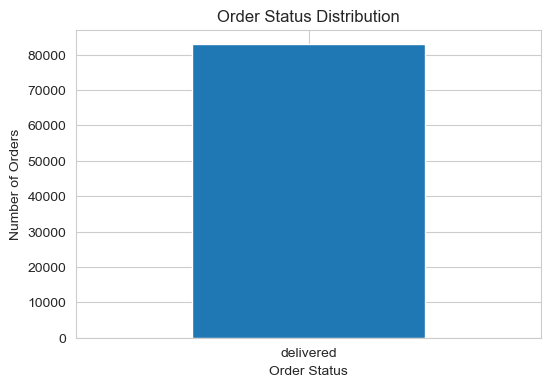

In [107]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))

order_status_counts.plot(kind='bar')

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

### Interpretation

The analysis shows that all 83,068 orders in the cleaned dataset have a delivered status. This indicates that the final dataset contains only successfully delivered orders after the data cleaning process.

## 2. Price Distribution

Product price is an important numerical variable in the Olist e-commerce dataset. Analyzing its distribution helps us understand the typical price range and identify how prices are spread across products.

In [108]:
# Price distribution summary

print("Price Statistics:")
print(master_df['price'].describe())

Price Statistics:
count    82871.000000
mean        77.394659
std         54.780088
min          0.850000
25%         35.000000
50%         59.900000
75%        105.000000
max        277.000000
Name: price, dtype: float64


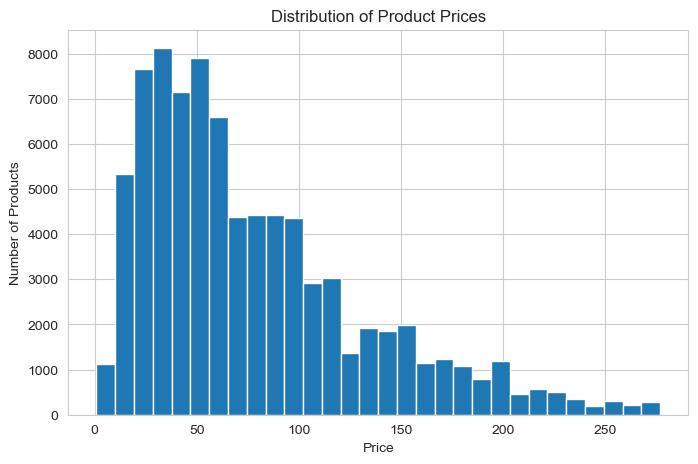

In [109]:
# Price distribution histogram

plt.figure(figsize=(8, 5))

plt.hist(master_df['price'], bins=30)

plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Number of Products')

plt.show()

### Interpretation

The product price distribution is concentrated mainly between 20 and 100. The number of products decreases as the price increases, indicating that lower-priced products are more common in the dataset. The distribution is right-skewed, with a smaller number of products having relatively high prices.

## 3. Review Score Distribution

Customer review scores help us understand the overall satisfaction level of customers with their purchases.

In [110]:
# Review score distribution

review_score_counts = master_df['average_review_score'].value_counts().sort_index()

print("Review Score Distribution:")
print(review_score_counts)

Review Score Distribution:
average_review_score
1.000000     7039
1.500000       12
2.000000     2468
2.500000       29
3.000000     6917
3.333333        1
3.500000       26
4.000000    16343
4.333333        1
4.500000       55
5.000000    49980
Name: count, dtype: int64


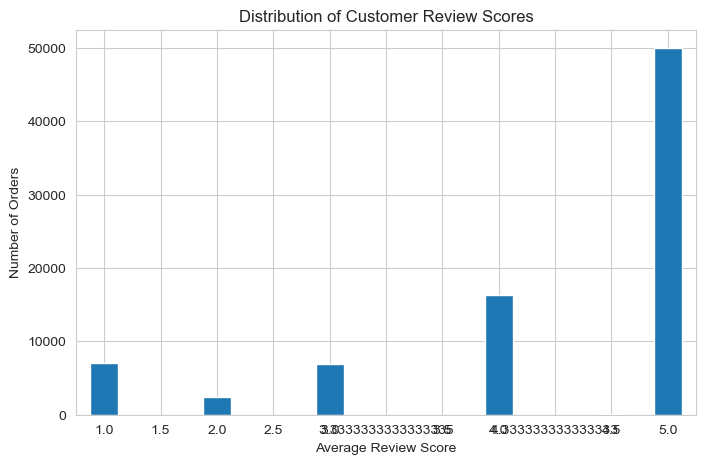

In [111]:
# Review score distribution

plt.figure(figsize=(8, 5))

review_score_counts.plot(kind='bar')

plt.title('Distribution of Customer Review Scores')
plt.xlabel('Average Review Score')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)

plt.show()

### Insight:
Most customer reviews are concentrated at 5 stars, indicating a generally high level of customer satisfaction. Four-star reviews are the second most common, while lower ratings occur less frequently.

## EDA – Monthly Order Trend

Analyzing monthly order trends helps identify how order volume changes over time and reveals periods of higher or lower customer activity.

In [112]:
# Arrange months in chronological order

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_orders = master_df.groupby('purchase_month_name').size()

monthly_orders = monthly_orders.reindex(month_order)

print(monthly_orders)

purchase_month_name
January      6503
February     6858
March        7915
April        7833
May          8932
June         7851
July         8818
August       9560
September    3691
October      3991
November     6288
December     4631
dtype: int64


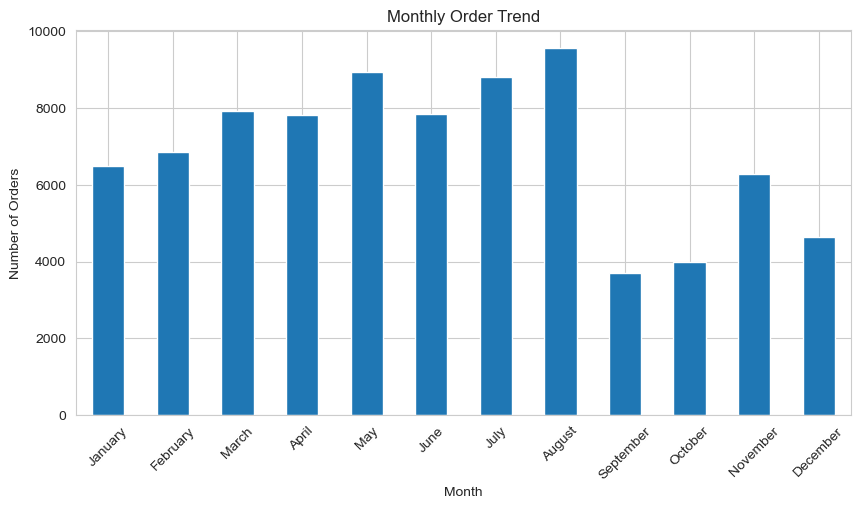

In [113]:
plt.figure(figsize=(10, 5))

monthly_orders.plot(kind='bar')

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)

plt.show()

### Interpretation

The monthly order trend shows variations in order volume throughout the year. August has the highest number of orders, while September has the lowest. Order volumes are relatively high from January to August, followed by a noticeable decline in September and October. Orders increase again in November and decrease slightly in December. These patterns help identify changes in customer purchasing activity across different months.

## EDA – Orders by Product Category

Analyzing orders by product category helps identify which product categories have the highest demand among customers.

In [114]:
# Orders by product category

category_orders = master_df['product_category_name_english'].value_counts().head(10)

print("Top 10 Product Categories by Number of Orders:")
print(category_orders)

Top 10 Product Categories by Number of Orders:
product_category_name_english
bed_bath_table           9061
health_beauty            7255
sports_leisure           6804
furniture_decor          6134
computers_accessories    5748
housewares               5413
watches_gifts            4055
telephony                3708
toys                     3203
auto                     3101
Name: count, dtype: int64


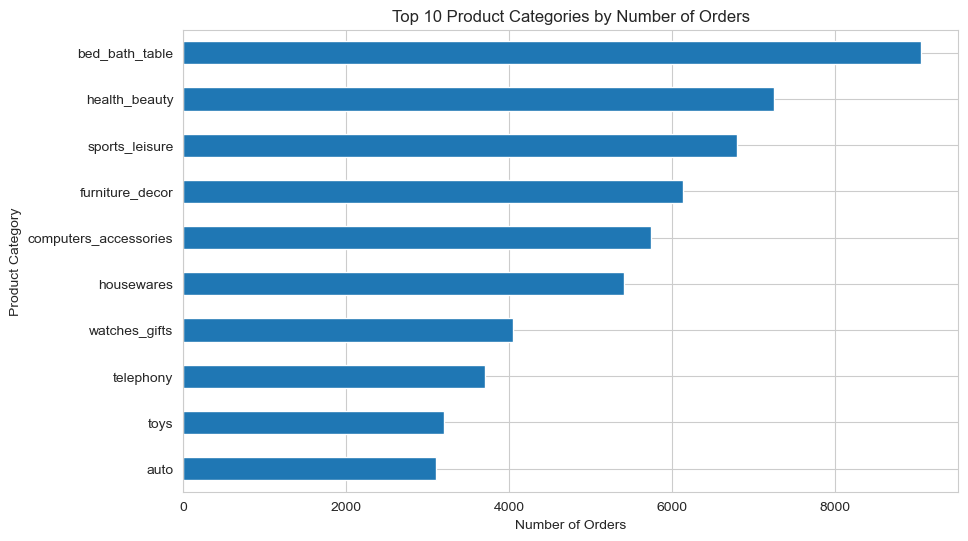

In [115]:
plt.figure(figsize=(10, 6))

category_orders.sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Product Category')

plt.show()

### Interpretation
The analysis shows that bed and bath products have the highest number of occurrences among the top 10 product categories, followed by health and beauty and sports and leisure. Auto and toys have fewer occurrences among these categories. These results help identify popular product categories and understand customer purchasing patterns.

## EDA – Revenue by Product Category

Analyzing revenue by product category helps identify which product categories generate the highest sales revenue and contribute most to the business.

Top 10 Product Categories by Revenue:
product_category_name_english
bed_bath_table           746116.60
sports_leisure           562393.74
health_beauty            559487.61
computers_accessories    466526.87
watches_gifts            457592.44
furniture_decor          414967.94
housewares               348615.51
cool_stuff               311501.55
toys                     266745.83
auto                     257342.03
Name: price, dtype: float64


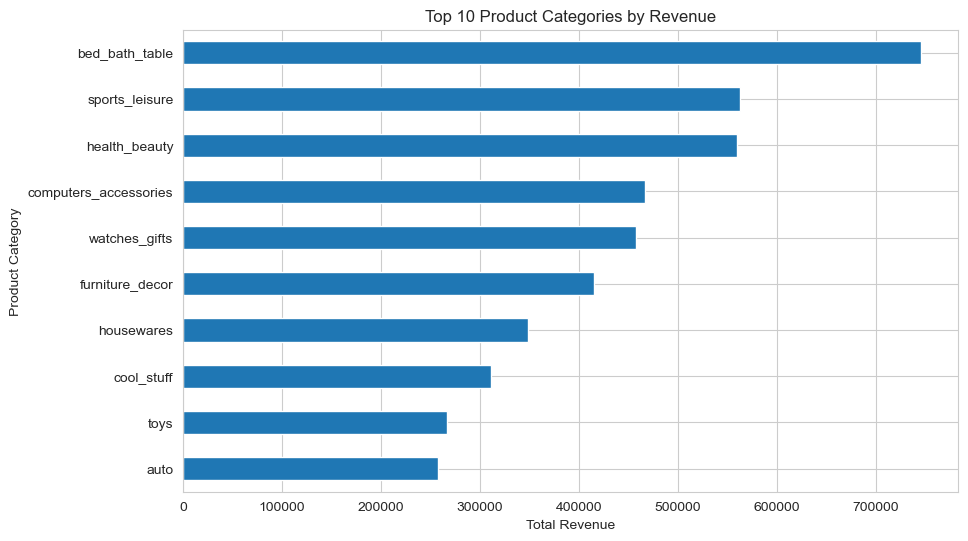

In [117]:
# Revenue by Product Category

category_revenue = master_df.groupby(
    'product_category_name_english'
)['price'].sum().sort_values(ascending=False).head(10)

print("Top 10 Product Categories by Revenue:")
print(category_revenue)

plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')

plt.show()

### Interpretation

The analysis shows that bed and bath products generate the highest revenue among the top 10 product categories, followed by sports and leisure and health and beauty. Auto and toys generate comparatively lower revenue among these categories. These findings help identify the product categories that contribute most to sales revenue and support better business decisions.

In [118]:
print(master_df.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


## EDA – Order Payment Value Analysis
Analyzing order payment values helps us understand how much customers spend on their purchases. This analysis provides insights into customer spending patterns and order values.

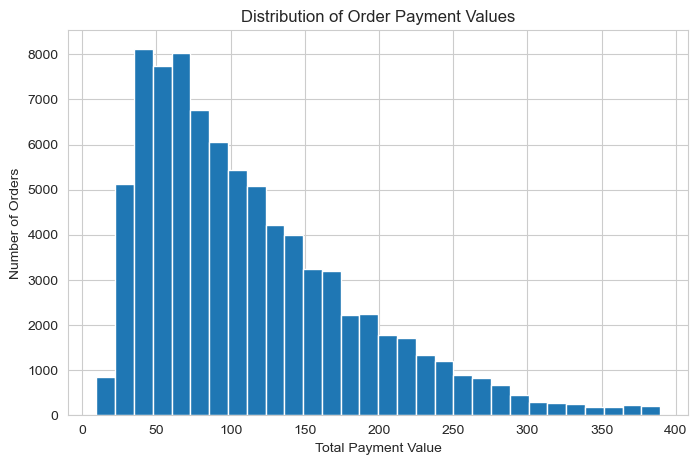

In [119]:
# Order payment value distribution

plt.figure(figsize=(8, 5))

plt.hist(master_df['total_payment_value'].dropna(), bins=30)

plt.title('Distribution of Order Payment Values')
plt.xlabel('Total Payment Value')
plt.ylabel('Number of Orders')

plt.show()

### Interpretation
The histogram shows that most order payment values are concentrated between approximately 30 and 150. As the payment value increases, the number of orders gradually decreases. The distribution is right-skewed, indicating that most customers place relatively low-value orders, while a smaller number of orders have higher payment values.

In [120]:
print(master_df.columns.tolist())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'price', 'freight_value', 'seller_city', 'seller_state', 'total_payment_value', 'average_review_score', 'seller_latitude', 'seller_longitude', 'item_revenue', 'purchase_year', 'purchase_month', 'purchase_month_name', 'purchase_day', 'delivery_days', 'delivery_delay_days', 'purchase_month_year', 'product_category_name_english']


## EDA - Delivery Delay Analysis
Delivery delay analysis helps us understand whether orders reach customers before or after the estimated delivery date. This analysis provides insights into delivery performance and customer satisfaction.

In [121]:
print(master_df['delivery_delay_days'].describe())

count    82871.000000
mean       -12.478889
std          6.898167
min        -32.000000
25%        -17.000000
50%        -13.000000
75%         -8.000000
max          8.000000
Name: delivery_delay_days, dtype: float64


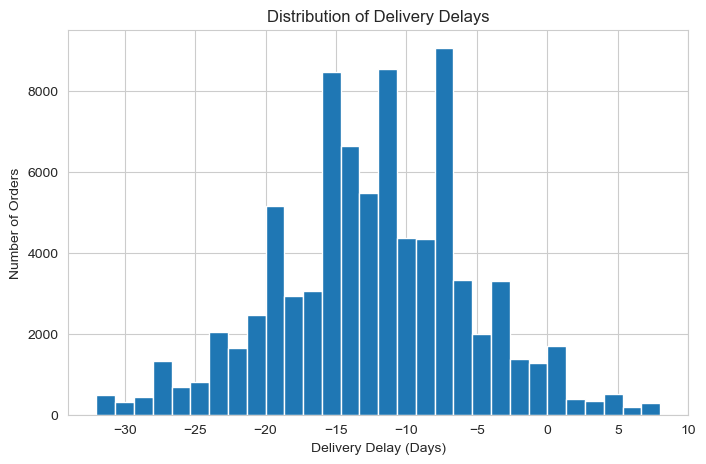

In [122]:
plt.figure(figsize=(8, 5))

plt.hist(master_df['delivery_delay_days'].dropna(), bins=30)

plt.title('Distribution of Delivery Delays')
plt.xlabel('Delivery Delay (Days)')
plt.ylabel('Number of Orders')

plt.show()

### Interpretation
The delivery delay distribution shows that most orders were delivered before their estimated delivery dates. The average delivery delay is approximately -12.48 days, indicating that orders were delivered about 12.48 days earlier than estimated, on average.

The minimum value is -32 days, while the maximum is 8 days. Negative values indicate early deliveries, whereas positive values indicate late deliveries. Therefore, the dataset suggests that most orders were delivered ahead of schedule, although some orders experienced delays.

## EDA – Customer Satisfaction by Product Category
Analyzing customer review scores by product category helps identify which product categories receive higher or lower customer ratings. This analysis can provide insights into customer satisfaction.

Average Review Score by Product Category:
product_category_name_english
fashion_childrens_clothes                5.000000
cds_dvds_musicals                        4.615385
books_general_interest                   4.597849
small_appliances_home_oven_and_coffee    4.551724
furniture_bedroom                        4.538462
food_drink                               4.518519
flowers                                  4.517241
cine_photo                               4.500000
books_imported                           4.490909
fashion_sport                            4.444444
Name: average_review_score, dtype: float64


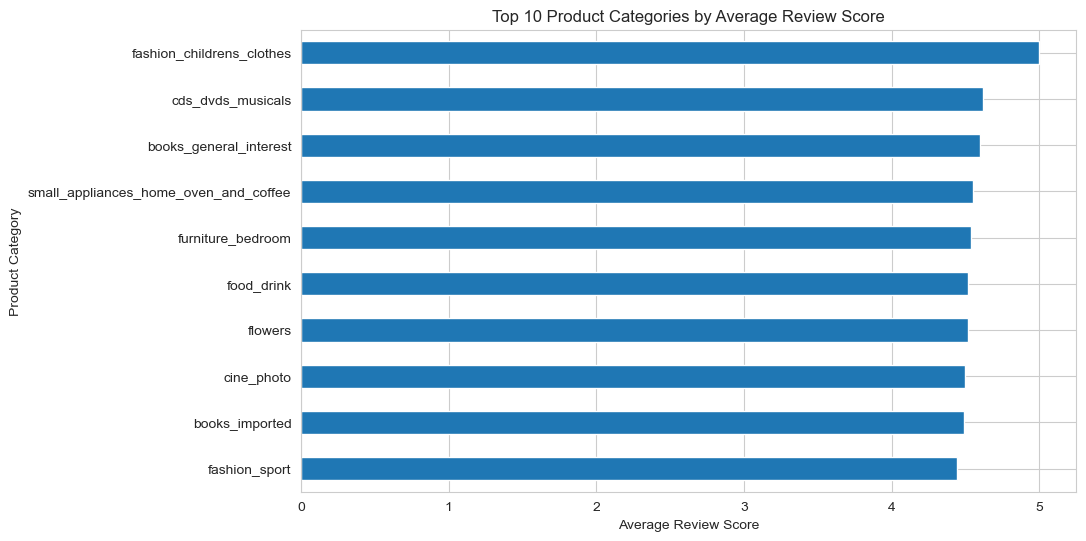

In [124]:
# Average review score by product category

category_reviews = master_df.groupby(
    'product_category_name_english'
)['average_review_score'].mean().sort_values(ascending=False)

print("Average Review Score by Product Category:")
print(category_reviews.head(10))

plt.figure(figsize=(10, 6))

category_reviews.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Average Review Score')
plt.xlabel('Average Review Score')
plt.ylabel('Product Category')

plt.show()

### Interpretation
The analysis shows that the fashion_children_clothes category has the highest average review score among the top 10 categories, at approximately 5.0. Other categories, including cds_dvds_musicals, books_general_interest, and small_appliances_home_oven_and_coffee, also have high average review scores.

These results suggest that customers generally gave positive ratings to products in these categories.

### EDA – Review Count by Product Category

Customer review counts help us understand how many orders have review scores in each product category. This analysis helps us compare customer feedback across different product categories.

Top 10 Product Categories by Review Count:
product_category_name_english
bed_bath_table           9061
health_beauty            7255
sports_leisure           6804
furniture_decor          6134
computers_accessories    5748
housewares               5413
watches_gifts            4055
telephony                3708
toys                     3203
auto                     3101
Name: average_review_score, dtype: int64


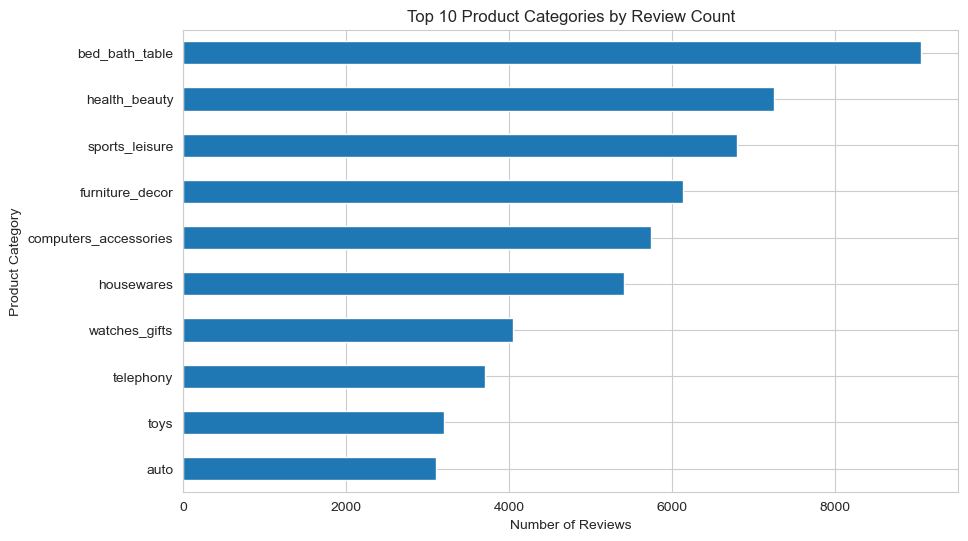

In [125]:
# Review count by product category

category_review_counts = master_df.groupby(
    'product_category_name_english'
)['average_review_score'].count().sort_values(ascending=False)

print("Top 10 Product Categories by Review Count:")
print(category_review_counts.head(10))

plt.figure(figsize=(10, 6))

category_review_counts.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Review Count')
plt.xlabel('Number of Reviews')
plt.ylabel('Product Category')

plt.show()

### Interpretation

The analysis shows that bed_bath_table has the highest number of review scores among the top 10 product categories, followed by health_beauty and sports_leisure. Categories such as toys and auto have fewer review scores among these top categories.

These results indicate that bed and bath products receive more customer reviews than the other categories shown. This may reflect their higher order volume.

## EDA – Average Price by Product Category
Analyzing average product prices across categories helps us identify which categories contain relatively expensive or inexpensive products. This analysis provides insights into product pricing across the e-commerce business.

Top 10 Product Categories by Average Price:
product_category_name_english
furniture_mattress_and_upholstery    144.750000
security_and_services                141.645000
office_furniture                     124.343500
home_appliances_2                    121.641039
la_cuisine                           116.199000
furniture_bedroom                    114.830256
watches_gifts                        112.846471
cool_stuff                           111.091851
home_confort                         108.608690
air_conditioning                     107.825230
Name: price, dtype: float64


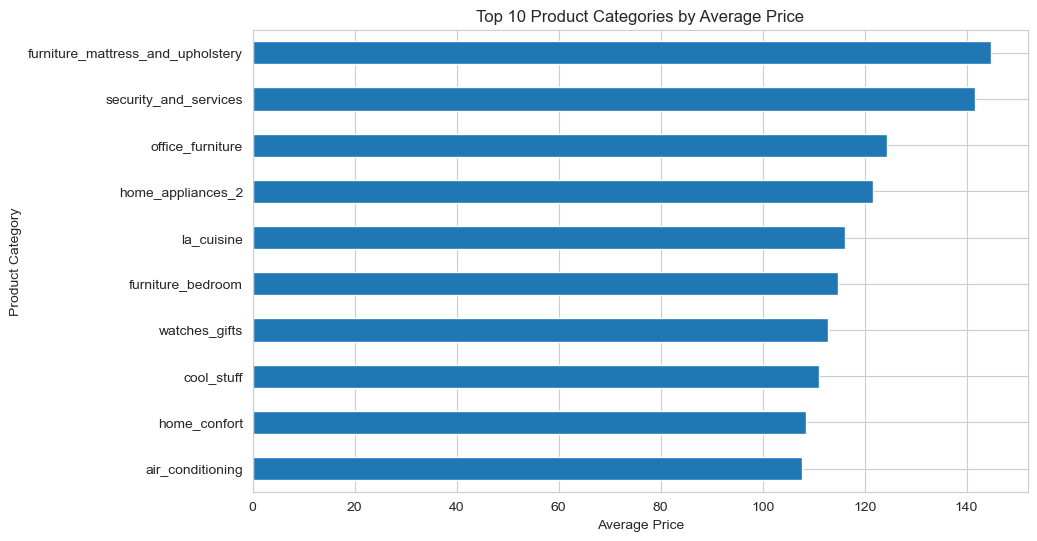

In [126]:
# Average price by product category

category_avg_price = master_df.groupby(
    'product_category_name_english'
)['price'].mean().sort_values(ascending=False)

print("Top 10 Product Categories by Average Price:")
print(category_avg_price.head(10))

plt.figure(figsize=(10, 6))

category_avg_price.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Average Price')
plt.xlabel('Average Price')
plt.ylabel('Product Category')

plt.show()

### Interpretation 

The analysis shows that furniture_mattress_and_upholstery has the highest average product price (approximately 144.75), followed by security_and_services (141.65) and office_furniture (124.34). These categories have higher average prices than the other categories in the top 10. This analysis helps identify product categories with higher-priced products.

## Top 10 Product Categories by Total Revenue

In [127]:
# Top 10 Product Categories by Total Revenue

category_revenue = master_df.groupby(
    'product_category_name_english'
)['item_revenue'].sum().sort_values(ascending=False).head(10)

print("Top 10 Product Categories by Total Revenue:")
print(category_revenue)

Top 10 Product Categories by Total Revenue:
product_category_name_english
bed_bath_table           892854.87
sports_leisure           670520.61
health_beauty            668480.81
computers_accessories    555085.34
watches_gifts            517803.76
furniture_decor          514611.55
housewares               435563.69
cool_stuff               358550.58
toys                     316200.23
auto                     307569.33
Name: item_revenue, dtype: float64


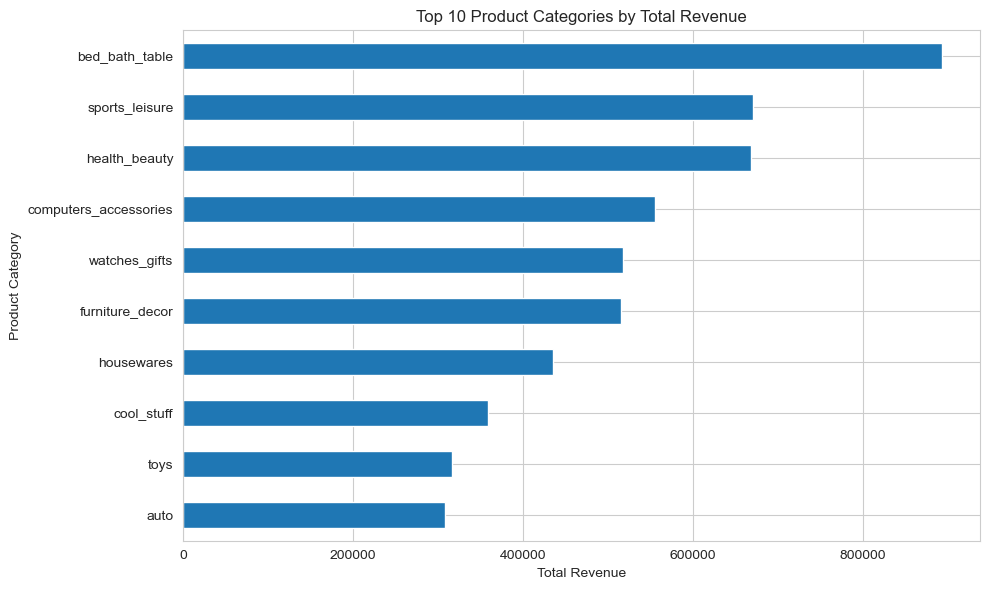

In [128]:
plt.figure(figsize=(10, 6))

category_revenue.sort_values().plot(kind='barh')

plt.title('Top 10 Product Categories by Total Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

### Interpretation

The analysis shows that bed_bath_table generates the highest total revenue among the top 10 product categories, followed by sports_leisure and health_beauty. The auto and toys categories generate comparatively lower revenue among these categories. These findings help identify the major revenue-generating product categories and support business decisions related to sales and marketing strategies.

# Final Insights and Business Recommendations

## Key Findings

1. Product Categories: Bed and bath products generate the highest total revenue among the top 10 product categories.

2. Sales Trends: Monthly order analysis helps identify changes in customer purchasing activity.

3. Payment Analysis: Most order payment values are concentrated in lower payment ranges.

4. Delivery Performance: Delivery delay analysis helps evaluate delivery performance.

5. Customer Reviews: Review analysis helps understand customer feedback across product categories.

## Business Recommendations

1. Focus on high-revenue product categories to improve sales.
2. Use monthly sales trends to plan inventory and promotions.
3. Analyze delivery delays and identify opportunities to improve logistics.
4. Monitor customer reviews to improve customer satisfaction.
5. Use sales and payment analysis to support business decisions.